In [4]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.utils.db import get_engine
engine = get_engine()
def q(sql: str, params: dict | None = None) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

from src.analysis.event_study import fetch_daily, event_study

In [5]:
GROUPS = """CASE WHEN carrier_code = 'DL' THEN 'Delta (DL)'
              WHEN carrier_code = '9E' THEN 'Endeavor Air (9E, Delta Connection)'
              ELSE 'All other airlines' END"""

daily = fetch_daily(q, "2024-06-01", "2024-08-15", GROUPS)
ev, summary = event_study(daily, "2024-07-19", "2024-08-05")
summary

,group,baseline_rate,peak_rate,peak_date,recovery_date,days_to_recover,excess_flights
0,All other airlines,1.56,10.9,2024-07-19,2024-07-21,2,2317
1,Delta (DL),0.16,47.4,2024-07-21,2024-07-25,6,5753
2,"Endeavor Air (9E, Delta Connection)",2.83,49.0,2024-07-19,2024-07-24,5,670


In [6]:
for tol in (0.5, 1.0, 2.0):
    _, s = event_study(daily, "2024-07-19", "2024-08-05", tolerance_pts=tol)
    print(f"tolerance {tol} pts")
    print(s[["group", "recovery_date", "days_to_recover"]].to_string(index=False), "\n")

tolerance 0.5 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-25                6
Endeavor Air (9E, Delta Connection)    2024-07-24                5 

tolerance 1.0 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-25                6
Endeavor Air (9E, Delta Connection)    2024-07-24                5 

tolerance 2.0 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-24                5
Endeavor Air (9E, Delta Connection)    2024-07-24                5 



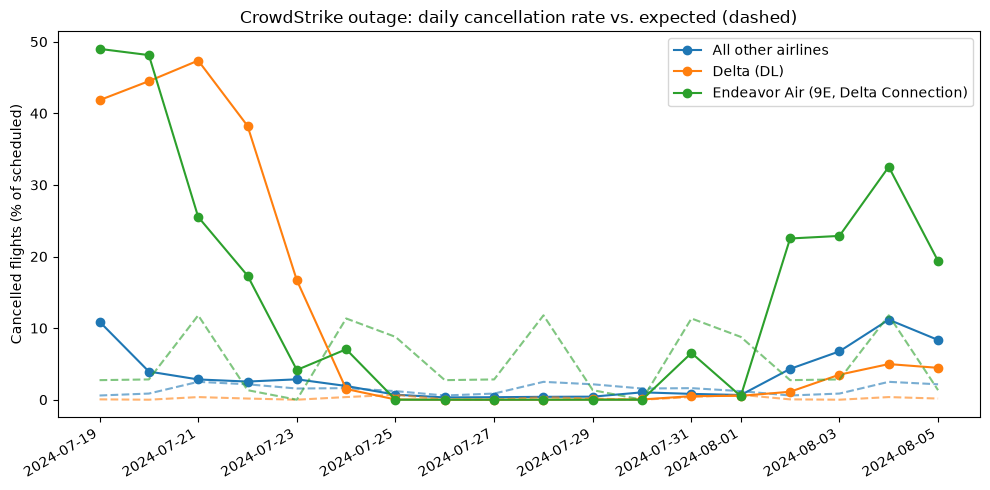

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for grp, g in ev.groupby("grp"):
    g = g.sort_values("full_date")
    (line,) = ax.plot(g["full_date"], g["cancel_rate"], marker="o", label=grp)
    ax.plot(g["full_date"], g["expected_rate"], linestyle="--", color=line.get_color(), alpha=0.6)
ax.set_ylabel("Cancelled flights (% of scheduled)")
ax.set_title("CrowdStrike outage: daily cancellation rate vs. expected (dashed)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "event_study_crowdstrike.png", dpi=150)
plt.show()

In [8]:
daily_all = q("""
SELECT full_date, day_of_week,
       COUNT(*)                             AS scheduled,
       COUNT(*) FILTER (WHERE is_cancelled) AS cancelled
FROM analytics.v_flights
GROUP BY 1, 2 ORDER BY 1
""")
daily_all["full_date"] = pd.to_datetime(daily_all["full_date"])
daily_all["cancel_rate"] = 100.0 * daily_all["cancelled"] / daily_all["scheduled"]

def robust_z(series: pd.Series, window: int = 9) -> pd.Series:
    med = series.rolling(window, center=True, min_periods=5).median()
    mad = (series - med).abs().rolling(window, center=True, min_periods=5).median()
    return (series - med) / (1.4826 * mad.clip(lower=0.1))

Z_THRESHOLD = 4
daily_all["z"] = daily_all.groupby("day_of_week")["cancel_rate"].transform(robust_z)

flagged = daily_all[daily_all["z"] >= Z_THRESHOLD].sort_values("full_date").copy()
flagged["event_id"] = (flagged["full_date"].diff().dt.days.fillna(99) > 2).cumsum()

events = (flagged.groupby("event_id")
          .agg(start=("full_date", "min"), end=("full_date", "max"),
               days=("full_date", "size"),
              peak_cancel_rate=("cancel_rate", "max"), peak_z=("z", "max"))
          .reset_index(drop=True)
          .sort_values("peak_z", ascending=False))
events

,start,end,days,peak_cancel_rate,peak_z
38,2025-11-08,2025-11-13,6,12.131885,61.852644
15,2024-10-08,2024-10-11,4,9.410836,47.547538
10,2024-08-02,2024-08-06,4,10.844116,42.425987
8,2024-07-17,2024-07-20,4,16.526924,33.492944
19,2025-01-05,2025-01-10,5,15.979410,31.093075
14,2024-09-26,2024-09-27,2,5.294202,28.750298
7,2024-05-28,2024-06-01,3,5.360444,27.551371
5,2024-04-20,2024-04-20,1,4.008611,18.895865
17,2024-11-08,2024-11-08,1,4.497955,13.961682
20,2025-01-21,2025-01-22,2,10.159661,12.923183


In [12]:
daily_all[(daily_all["full_date"] >= "2024-07-14") & (daily_all["full_date"] <= "2024-07-21")][["full_date", "cancel_rate", "z"]]

,full_date,cancel_rate,z
195,2024-07-14,2.188744,-0.017554
196,2024-07-15,2.186201,0.342101
197,2024-07-16,1.665020,0.674491
198,2024-07-17,4.550115,4.244742
199,2024-07-18,4.726136,8.179595
200,2024-07-19,16.526924,30.733227
201,2024-07-20,10.683917,33.492944
202,2024-07-21,10.096131,2.718621


In [9]:
window = q("""
SELECT full_date, day_name,
       COUNT(*)                                                                       AS scheduled,
       COUNT(*) FILTER (WHERE is_cancelled)                                           AS cancelled,
       ROUND(100.0 * AVG(is_cancelled::int), 2)                                       AS pct_cancelled,
       ROUND(100.0 * COUNT(*) FILTER (WHERE cancellation_code = 'A') / COUNT(*), 2)   AS pct_carrier,
       ROUND(100.0 * COUNT(*) FILTER (WHERE cancellation_code = 'B') / COUNT(*), 2)   AS pct_weather,
       ROUND(100.0 * COUNT(*) FILTER (WHERE cancellation_code = 'C') / COUNT(*), 2)   AS pct_nas
FROM analytics.v_flights
WHERE full_date BETWEEN DATE '2025-10-27' AND DATE '2025-11-23'
GROUP BY full_date, day_name
ORDER BY full_date
""")
window

,full_date,day_name,scheduled,cancelled,pct_cancelled,pct_carrier,pct_weather,pct_nas
0,2025-10-27,Monday,20889,53,0.25,0.19,0.05,0.02
1,2025-10-28,Tuesday,17773,32,0.18,0.08,0.09,0.01
2,2025-10-29,Wednesday,18095,36,0.20,0.06,0.09,0.05
3,2025-10-30,Thursday,20224,851,4.21,0.85,1.15,2.22
4,2025-10-31,Friday,17091,337,1.97,0.64,0.59,0.74
5,2025-11-01,Saturday,16369,73,0.45,0.23,0.13,0.09
6,2025-11-02,Sunday,20032,105,0.52,0.10,0.08,0.34
7,2025-11-03,Monday,19351,24,0.12,0.08,0.02,0.03
8,2025-11-04,Tuesday,17584,74,0.42,0.14,0.01,0.10
9,2025-11-05,Wednesday,17823,98,0.55,0.11,0.05,0.36


In [10]:
faa = pd.read_csv(ROOT / "reference" / "faa_reduction_airports_2025.csv")
codes = faa["airport_code"].str.strip().str.upper().tolist()
print(len(codes), "airports in the list")

AFFECTED, OTHER = "Touches an FAA-listed airport", "Other flights"

by_group = q("""
SELECT full_date,
       CASE WHEN origin = ANY(:codes) OR dest = ANY(:codes) THEN :affected ELSE :other END AS grp,
       COUNT(*)                             AS scheduled,
       COUNT(*) FILTER (WHERE is_cancelled) AS cancelled
FROM analytics.v_flights
WHERE full_date BETWEEN DATE '2025-10-20' AND DATE '2025-11-30'
GROUP BY 1, 2
ORDER BY 1, 2
""", {"codes": codes, "affected": AFFECTED, "other": OTHER})

by_group["full_date"] = pd.to_datetime(by_group["full_date"])
by_group["pct_cancelled"] = 100.0 * by_group["cancelled"] / by_group["scheduled"]
wide = by_group.pivot(index="full_date", columns="grp", values="pct_cancelled")
wide["gap_pts"] = wide[AFFECTED] - wide[OTHER]
wide.round(2)

40 airports in the list


grp,Other flights,Touches an FAA-listed airport,gap_pts
full_date,,,
2025-10-20,0.00,0.14,0.14
2025-10-21,0.00,0.08,0.08
2025-10-22,0.76,0.11,-0.65
2025-10-23,1.34,0.87,-0.47
2025-10-24,4.04,1.72,-2.33
2025-10-25,0.00,0.69,0.69
2025-10-26,0.26,0.40,0.15
2025-10-27,0.27,0.25,-0.02
2025-10-28,0.40,0.17,-0.23


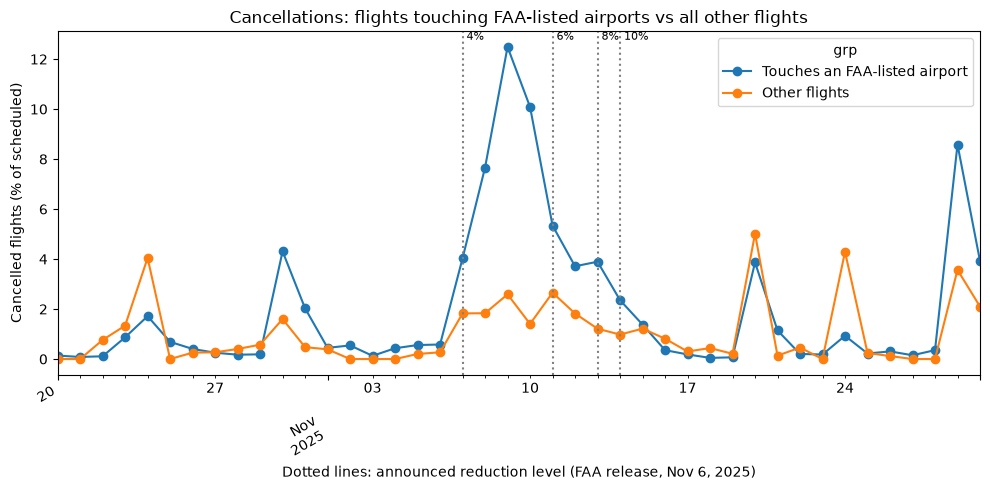

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
wide[[AFFECTED, OTHER]].plot(ax=ax, marker="o")
for day, label in [("2025-11-07", "4%"), ("2025-11-11", "6%"),
                   ("2025-11-13", "8%"), ("2025-11-14", "10%")]:
    ax.axvline(pd.Timestamp(day), linestyle=":", color="grey")
    ax.text(pd.Timestamp(day), ax.get_ylim()[1], f" {label}", va="top", fontsize=8)
ax.set_ylabel("Cancelled flights (% of scheduled)")
ax.set_xlabel("Dotted lines: announced reduction level (FAA release, Nov 6, 2025)")
ax.set_title("Cancellations: flights touching FAA-listed airports vs all other flights")
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "faa_reductions_2025.png", dpi=150)
plt.show()

In [13]:
q("""
SELECT full_date, origin,
       COUNT(*) FILTER (WHERE is_cancelled) AS cancelled,
       COUNT(*) FILTER (WHERE cancellation_code = 'B') AS weather_coded
FROM analytics.v_flights
WHERE full_date IN (DATE '2024-07-17', DATE '2024-07-18')
GROUP BY 1, 2 ORDER BY 1, 3 DESC
""").groupby("full_date").head(5)

,full_date,origin,cancelled,weather_coded
0,2024-07-17,LGA,116,29
1,2024-07-17,JFK,72,10
2,2024-07-17,EWR,69,34
3,2024-07-17,CLT,55,49
4,2024-07-17,DCA,44,32
338,2024-07-18,CLT,86,66
339,2024-07-18,LAS,55,30
340,2024-07-18,LAX,48,12
341,2024-07-18,DFW,46,20
342,2024-07-18,ATL,46,11


In [14]:
ops = q("""
SELECT full_date, day_of_week,
       COUNT(*) FILTER (WHERE (origin = ANY(:codes) OR dest = ANY(:codes))
                        AND NOT is_cancelled) AS affected_operated,
       COUNT(*) FILTER (WHERE NOT (origin = ANY(:codes) OR dest = ANY(:codes))
                        AND NOT is_cancelled) AS other_operated
FROM analytics.v_flights
WHERE full_date BETWEEN DATE '2025-10-13' AND DATE '2025-11-30'
GROUP BY 1, 2 ORDER BY 1
""", {"codes": codes})
ops["full_date"] = pd.to_datetime(ops["full_date"])

base = ops[ops["full_date"] <= "2025-11-06"]
base_med = base.groupby("day_of_week")[["affected_operated", "other_operated"]].median()

ev = ops[ops["full_date"] >= "2025-11-07"].join(base_med, on="day_of_week", rsuffix="_base")
ev["affected_change_pct"] = 100 * (ev["affected_operated"] / ev["affected_operated_base"] - 1)
ev["other_change_pct"]    = 100 * (ev["other_operated"] / ev["other_operated_base"] - 1)
ev[["full_date", "affected_change_pct", "other_change_pct"]].round(1)

C:\Users\Mohamad\AppData\Local\Temp\ipykernel_12544\222286972.py:16: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  ev = ops[ops["full_date"] >= "2025-11-07"].join(base_med, on="day_of_week", rsuffix="_base")
C:\Users\Mohamad\AppData\Local\Temp\ipykernel_12544\222286972.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ev[["full_date", "affected_change_pct", "other_change_pct"]].round(1)


,full_date,affected_change_pct,other_change_pct
25,2025-11-07,-6.9,1.6
26,2025-11-08,-8.8,-9.2
27,2025-11-09,-13.6,-7.5
28,2025-11-10,-12.5,-4.0
29,2025-11-11,-6.3,-11.2
30,2025-11-12,-6.5,-6.6
31,2025-11-13,-3.7,-0.7
32,2025-11-14,-3.7,2.9
33,2025-11-15,-2.7,-8.3
34,2025-11-16,-1.8,-5.4


In [15]:
ops = q("""
SELECT full_date, day_of_week, is_federal_holiday,
       COUNT(*) FILTER (WHERE touch)                          AS aff_sched,
       COUNT(*) FILTER (WHERE touch AND NOT is_cancelled)     AS aff_oper,
       COUNT(*) FILTER (WHERE NOT touch)                      AS oth_sched,
       COUNT(*) FILTER (WHERE NOT touch AND NOT is_cancelled) AS oth_oper
FROM (SELECT *, (origin = ANY(:codes) OR dest = ANY(:codes)) AS touch
      FROM analytics.v_flights
      WHERE full_date BETWEEN DATE '2025-10-06' AND DATE '2025-11-23') t
GROUP BY 1, 2, 3
ORDER BY 1
""", {"codes": codes})
ops["full_date"] = pd.to_datetime(ops["full_date"])

cols = ["aff_sched", "aff_oper", "oth_sched", "oth_oper"]
base = ops[(ops["full_date"] <= "2025-11-02") & (~ops["is_federal_holiday"].astype(bool))]
base_med = base.groupby("day_of_week")[cols].median()

ev = ops[ops["full_date"] >= "2025-11-03"].join(base_med, on="day_of_week", rsuffix="_b")
for c in cols:
    ev[c + "_chg"] = 100 * (ev[c] / ev[c + "_b"] - 1)
ev["net_oper_chg"]  = ev["aff_oper_chg"]  - ev["oth_oper_chg"]
ev["net_sched_chg"] = ev["aff_sched_chg"] - ev["oth_sched_chg"]

ev[["full_date", "aff_oper_chg", "oth_oper_chg", "net_oper_chg", "net_sched_chg"]].round(1)

C:\Users\Mohamad\AppData\Local\Temp\ipykernel_12544\604938874.py:19: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  ev = ops[ops["full_date"] >= "2025-11-03"].join(base_med, on="day_of_week", rsuffix="_b")
C:\Users\Mohamad\AppData\Local\Temp\ipykernel_12544\604938874.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ev[["full_date", "aff_oper_chg", "oth_oper_chg", "net_oper_chg", "net_sched_chg"]].round(1)


,full_date,aff_oper_chg,oth_oper_chg,net_oper_chg,net_sched_chg
28,2025-11-03,-7.5,-8.2,0.7,1.0
29,2025-11-04,-5.1,-8.8,3.7,4.1
30,2025-11-05,-5.3,-7.9,2.6,3.3
31,2025-11-06,-4.3,-1.8,-2.5,-1.7
32,2025-11-07,-8.2,-1.5,-6.7,-3.5
33,2025-11-08,-9.0,-13.2,4.3,9.3
34,2025-11-09,-13.9,-7.1,-6.8,3.2
35,2025-11-10,-13.0,-3.8,-9.2,-0.6
36,2025-11-11,-8.3,-11.2,2.9,5.7
37,2025-11-12,-8.2,-9.4,1.3,3.5
